# 01. Przegląd danych PTB-XL

Cel: zobaczyć, jakie są dane, jakie mają etykiety i gdzie siedzi niepewność, zanim zbudujemy modele.

1. Ogólne informacje
2. Etykiety i podział na zbiory
3. Pewność diagnozy
4. Jakość sygnału i weryfikacja opisu
5. Sygnały EKG
6. Wnioski

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.data import CLASSES, LEADS, NOISE_COLUMNS, load_metadata, load_signals

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

df = load_metadata()
X = load_signals()  # (N, 1000, 12), za pierwszym razem ok. 1 min
X.shape

/opt/homebrew/Caskroom/miniconda/base/envs/prob-clf/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(21837, 1000, 12)

## 1. Ogólne informacje

In [2]:
print(f"Zapisy:    {len(df):,}")
print(f"Pacjenci:  {df.patient_id.nunique():,}")
print(f"Sygnał:    {X.shape[1]} próbek x {X.shape[2]} odprowadzeń (100 Hz, 10 s)")
print(f"Kobiety / mężczyźni: {(df.sex == 1).sum():,} / {(df.sex == 0).sum():,}")
df[["age", "height", "weight"]].describe().round(1)

Zapisy:    21,837
Pacjenci:  18,885
Sygnał:    1000 próbek x 12 odprowadzeń (100 Hz, 10 s)
Kobiety / mężczyźni: 10,458 / 11,379


,age,height,weight
count,21748.0,6983.0,9429.0
mean,59.8,166.7,71.0
std,17.0,10.9,15.9
min,2.0,6.0,5.0
25%,50.0,160.0,60.0
50%,62.0,166.0,70.0
75%,72.0,174.0,80.0
max,95.0,209.0,250.0


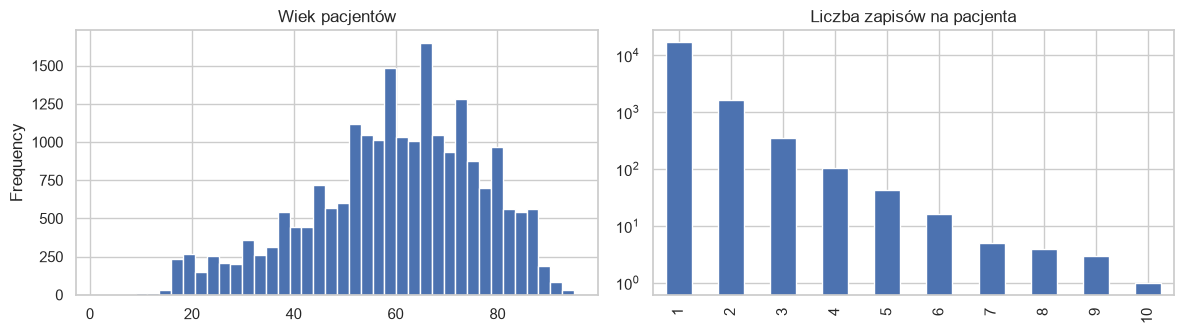

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
df.age.plot.hist(bins=40, ax=axes[0], title="Wiek pacjentów")
df.groupby("patient_id").size().value_counts().sort_index().plot.bar(
    ax=axes[1], title="Liczba zapisów na pacjenta", logy=True)
plt.tight_layout()

## 2. Etykiety i podział na zbiory

Każdy zapis ma listę kodów diagnoz (`scp_codes`), które grupujemy w 5 nadklas.
Jeden zapis może mieć kilka nadklas naraz albo żadnej.

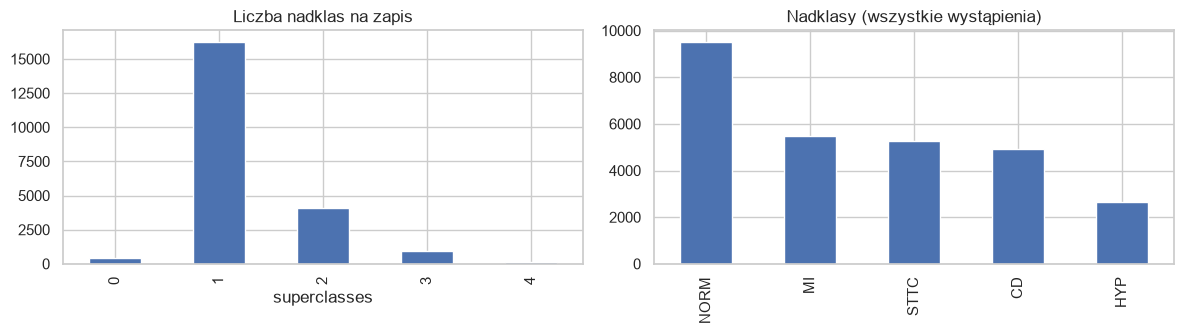

In [4]:
n_classes = df.superclasses.apply(len)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
n_classes.value_counts().sort_index().plot.bar(ax=axes[0], title="Liczba nadklas na zapis")
pd.Series([c for s in df.superclasses for c in s]).value_counts()[CLASSES].plot.bar(
    ax=axes[1], title="Nadklasy (wszystkie wystąpienia)")
plt.tight_layout()

In [5]:
# Najczęstsze kombinacje nadklas
df.superclasses.apply(lambda s: "+".join(s) or "(brak)").value_counts().head(12)

superclasses
NORM           9083
MI             2538
STTC           2406
CD             1709
CD+MI          1302
HYP+STTC        783
MI+STTC         602
HYP             536
CD+STTC         472
(brak)          407
CD+NORM         407
HYP+MI+STTC     362
Name: count, dtype: int64

Na start bierzemy tylko zapisy z **dokładnie jedną** nadklasą (kolumna `label`).
Podział na zbiory jest po pacjentach: foldy 1–8 to trening, 9 walidacja, 10 test.

In [6]:
single = df[df.label.notna()]
counts = pd.crosstab(single.label, single.split).loc[CLASSES, ["train", "val", "test"]]
counts["razem"] = counts.sum(axis=1)
counts["udział"] = (counts.razem / counts.razem.sum()).round(3)
counts

split,train,val,test,razem,udział
label,,,,,
NORM,7254,916,913,9083,0.558
MI,2048,234,256,2538,0.156
STTC,1907,256,243,2406,0.148
CD,1353,172,184,1709,0.105
HYP,416,64,56,536,0.033


In [7]:
# Czy ten sam pacjent trafia do dwóch zbiorów?
splits_per_patient = df.groupby("patient_id").split.nunique()
print("Pacjenci w więcej niż jednym zbiorze:", (splits_per_patient > 1).sum())

Pacjenci w więcej niż jednym zbiorze: 0


## 3. Pewność diagnozy

Kolumna `likelihood` to pewność 0–100 dla diagnozy z etykiety. Autorzy bazy wyliczyli ją
ze sformułowania opisu, więc ma tylko kilka wartości.

In [8]:
lk = pd.crosstab(single.label, single.likelihood.fillna(0).astype(int)).loc[CLASSES]
lk

likelihood,0,15,35,50,80,100
label,,,,,,
NORM,0,30,31,432,1573,7017
MI,0,618,70,410,99,1341
STTC,13,5,3,184,32,2169
CD,0,1,0,23,52,1633
HYP,0,119,108,130,45,134


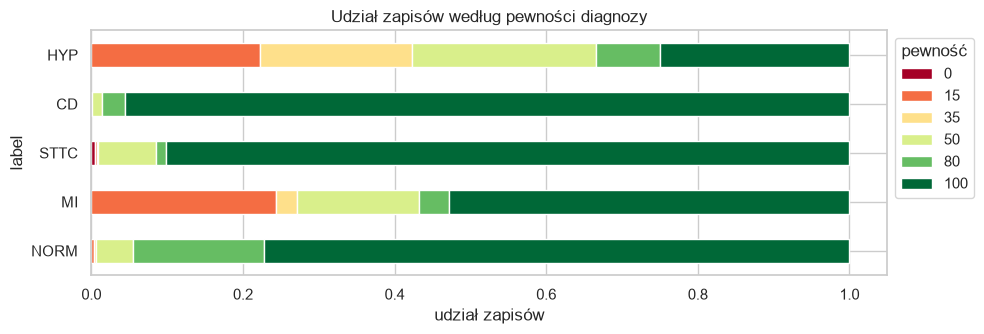

In [9]:
lk_share = lk.div(lk.sum(axis=1), axis=0)
lk_share.plot.barh(stacked=True, figsize=(10, 3.5), colormap="RdYlGn",
                   title="Udział zapisów według pewności diagnozy")
plt.xlabel("udział zapisów")
plt.legend(title="pewność", bbox_to_anchor=(1, 1))
plt.tight_layout()

### Pewność wszystkich diagnoz w bazie

Powyżej jest pewność tylko dla etykiety zapisów z jedną nadklasą. Poniżej pewność **każdej diagnozy**
(kodu diagnostycznego) w całej bazie, także w zapisach z kilkoma nadklasami.

In [10]:
from src.data import DATA_DIR

statements = pd.read_csv(DATA_DIR / "scp_statements.csv", index_col=0)
diagnostic = statements.loc[statements.diagnostic == 1, "diagnostic_class"]

all_diag = pd.DataFrame(
    [(ecg_id, code, diagnostic[code], value)
     for ecg_id, codes in df.scp_codes.items()
     for code, value in codes.items() if code in diagnostic.index],
    columns=["ecg_id", "kod", "nadklasa", "pewność"],
)
print(f"Diagnoz w bazie: {len(all_diag):,}")
pd.crosstab(all_diag.nadklasa, all_diag.pewność.astype(int), margins=True).loc[CLASSES + ["All"]]

Diagnoz w bazie: 30,793


pewność,0,10,14,15,30,34,35,50,80,100,All
nadklasa,,,,,,,,,,,
NORM,0,0,0,38,0,1,37,506,1761,7185,9528
MI,0,0,1,1498,0,0,157,1296,234,3700,6886
STTC,213,0,0,15,0,0,17,623,71,4849,5788
CD,0,1,0,4,1,0,3,67,58,5638,5772
HYP,0,0,0,203,0,0,204,757,98,1557,2819
All,213,1,1,1758,1,1,418,3249,2222,22929,30793


In [11]:
# Kody diagnoz najczęściej stawiane z niską pewnością (< 100)
low = all_diag[(all_diag.pewność > 0) & (all_diag.pewność < 100)]
top = low.kod.value_counts().head(10).rename("diagnoz z pewnością < 100").to_frame()
top["wszystkich diagnoz"] = all_diag.kod.value_counts()[top.index]
top["udział niskiej pewności"] = (top.iloc[:, 0] / top.iloc[:, 1]).round(2)
top["opis"] = statements.loc[top.index, "description"]
top

,diagnoz z pewnością < 100,wszystkich diagnoz,udział niskiej pewności,opis
kod,,,,
NORM,2343,9528,0.25,normal ECG
IMI,1660,2685,0.62,inferior myocardial infarction
LVH,1048,2137,0.49,left ventricular hypertrophy
ASMI,835,2363,0.35,anteroseptal myocardial infarction
AMI,238,354,0.67,anterior myocardial infarction
ISC_,153,1275,0.12,non-specific ischemic
ILMI,148,479,0.31,inferolateral myocardial infarction
LMI,144,201,0.72,lateral myocardial infarction
ISCAL,136,660,0.21,ischemic in anterolateral leads


### Skąd się bierze pewność: przykładowe opisy

Autorzy bazy wyliczyli pewność ze słów w opisie (po niemiecku albo angielsku). Typowe sformułowania, które widać w danych:

| Pewność | Typowe sformułowania |
|---|---|
| 15 | *nicht auszuschliessen* (nie można wykluczyć), *möglich* (możliwy), *verdacht auf* (podejrzenie) |
| 35 | *suggest(ing)* (sugeruje) |
| 50 | *wahrscheinlich* (prawdopodobnie) |
| 80 | *sonst normales EKG* (poza tym prawidłowe EKG), *consistent with* |
| 100 | diagnoza bez zastrzeżeń |

Ta tabela to obserwacja z danych, a nie oficjalne mapowanie. Pełne mapowanie jest w tabeli 4 publikacji o PTB-XL.

In [12]:
with pd.option_context("display.max_colwidth", 140):
    examples = single[single.likelihood.notna()].groupby("likelihood").sample(2, random_state=0)
    display(examples[["label", "likelihood", "report"]])

,label,likelihood,report
ecg_id,,,
11687,MI,15.0,ventrikulÄre extrasystole(n) sinusrhythmus a-v block i linkstyp mÄssige amplitudenkriterien fÜr linkshypertrophie qrs(t) abnorm anter...
18663,MI,15.0,sinusrhythmus verdacht auf p-sinistrocardiale lagetyp normal t abnorm in hochlateralen ableitungen qt-verlÄngerung 4.46 ...
6157,HYP,35.0,"premature atrial contraction(s), trigeminy. sinus rhythm. voltages are high in limb leads suggesting lvh."
9286,NORM,35.0,"sinusrhythmus llt links t-veraenderungen: neg. in iii, flach in avf,v1 wahrscheinlich normales ekg"
5635,MI,50.0,"sinusrhythmus ueberdrehter linkstyp qrs(t) abnormal inferiorer infarkt mÖglich st & t abnormal, wahrscheinlich hochlaterale ischÄm..."
12416,STTC,50.0,"sinusrhythmus lagetyp normal st & t abnormal, wahrscheinlich anterolaterale ischÄmie oder linksbelastung inferolaterale ischÄmie o..."
6407,NORM,80.0,sinusrhythmus linkstyp sonst normales ekg 4.46 unbestÄtigter bericht
2627,MI,80.0,"sinus arrhythmia. q waves in ii, iii, avf consistent with old inferior myocardial infarction."
9530,MI,100.0,sinusrhythmus lagetyp normal periphere niederspannung qrs(t) abnorm anterolateraler myokardschaden mÖglich t abnorm in anterioren abl...


### Pewność w zbiorze testowym

Do analizy „czy niepewność modelu rośnie przy niepewnej diagnozie” liczy się to, ile przykładów
każdego poziomu pewności mamy w **teście**, osobno dla każdej klasy.

In [13]:
test = single[single.split == "test"]
pd.crosstab(test.label, test.likelihood.fillna(0).astype(int), margins=True).loc[CLASSES + ["All"]]

likelihood,0,15,35,50,80,100,All
label,,,,,,,
NORM,0,2,5,47,155,704,913
MI,0,61,10,54,16,115,256
STTC,1,0,0,15,5,222,243
CD,0,0,0,3,7,174,184
HYP,0,8,21,11,4,12,56
All,1,71,36,130,187,1227,1652


Porównanie w obrębie klasy ma sens tylko tam, gdzie obie grupy (pewność 100 i < 100) są liczne:
w praktyce dla **NORM** i **MI**. W HYP przykładów jest za mało, a w CD i STTC prawie nie ma niepewnych etykiet.

In [14]:
# Czy niepewne etykiety częściej mają zaszumiony sygnał albo niepotwierdzony opis? (w obrębie klasy)
single.assign(niska_pewność=single.likelihood < 100).groupby(["label", "niska_pewność"])[
    ["noisy", "human_validated"]].mean().round(2).loc[CLASSES]

noisy  human_validated
label niska_pewność                        
NORM  False           0.22             0.84
      True            0.22             0.77
MI    False           0.31             0.51
      True            0.26             0.63
STTC  False           0.25             0.73
      True            0.24             0.73
CD    False           0.22             0.72
      True            0.09             0.91
HYP   False           0.25             0.76
      True            0.14             0.78

## 4. Jakość sygnału i weryfikacja opisu

Kolumny jakości opisują, które odprowadzenia są zaszumione (np. `, I-AVR,`).
`human_validated = False` oznacza, że opis mógł wygenerować aparat bez potwierdzenia przez lekarza.

In [15]:
quality = pd.DataFrame({
    "zapisów z problemem": df[NOISE_COLUMNS].notna().sum(),
    "udział": df[NOISE_COLUMNS].notna().mean().round(3),
})
quality.loc["jakikolwiek"] = [df.noisy.sum(), round(df.noisy.mean(), 3)]
quality

,zapisów z problemem,udział
static_noise,3262,0.149
burst_noise,613,0.028
baseline_drift,1607,0.074
electrodes_problems,30,0.001
jakikolwiek,5021,0.230


In [16]:
by_class = single.groupby("label")[["noisy", "human_validated"]].mean().loc[CLASSES]
by_class["niska pewność (<100)"] = single.groupby("label").likelihood.apply(lambda s: (s < 100).mean())
by_class.columns = ["zaszumiony sygnał", "opis potwierdzony", "niska pewność (<100)"]
by_class.round(3)

,zaszumiony sygnał,opis potwierdzony,niska pewność (<100)
label,,,
NORM,0.216,0.821,0.227
MI,0.283,0.562,0.472
STTC,0.245,0.727,0.093
CD,0.217,0.733,0.044
HYP,0.166,0.778,0.750


In [17]:
# Czy te źródła niepewności się pokrywają?
pd.crosstab(single.noisy, single.human_validated, margins=True)

human_validated,False,True,All
noisy,,,
False,2778,9763,12541
True,1190,2541,3731
All,3968,12304,16272


## 5. Sygnały EKG

In [18]:
def plot_ecg(ecg_id, title=None):
    signal = X[df.index.get_loc(ecg_id)]
    t = np.arange(signal.shape[0]) / 100
    fig, axes = plt.subplots(6, 2, figsize=(14, 8), sharex=True)
    for i, ax in enumerate(axes.T.flat):
        ax.plot(t, signal[:, i], lw=0.8)
        ax.set_ylabel(LEADS[i], rotation=0, labelpad=15)
    axes[-1, 0].set_xlabel("czas [s]")
    axes[-1, 1].set_xlabel("czas [s]")
    row = df.loc[ecg_id]
    fig.suptitle(title or f"ecg_id={ecg_id}  {row.label}  pewność={row.likelihood}  "
                 f"zaszumiony={row.noisy}")
    plt.tight_layout()

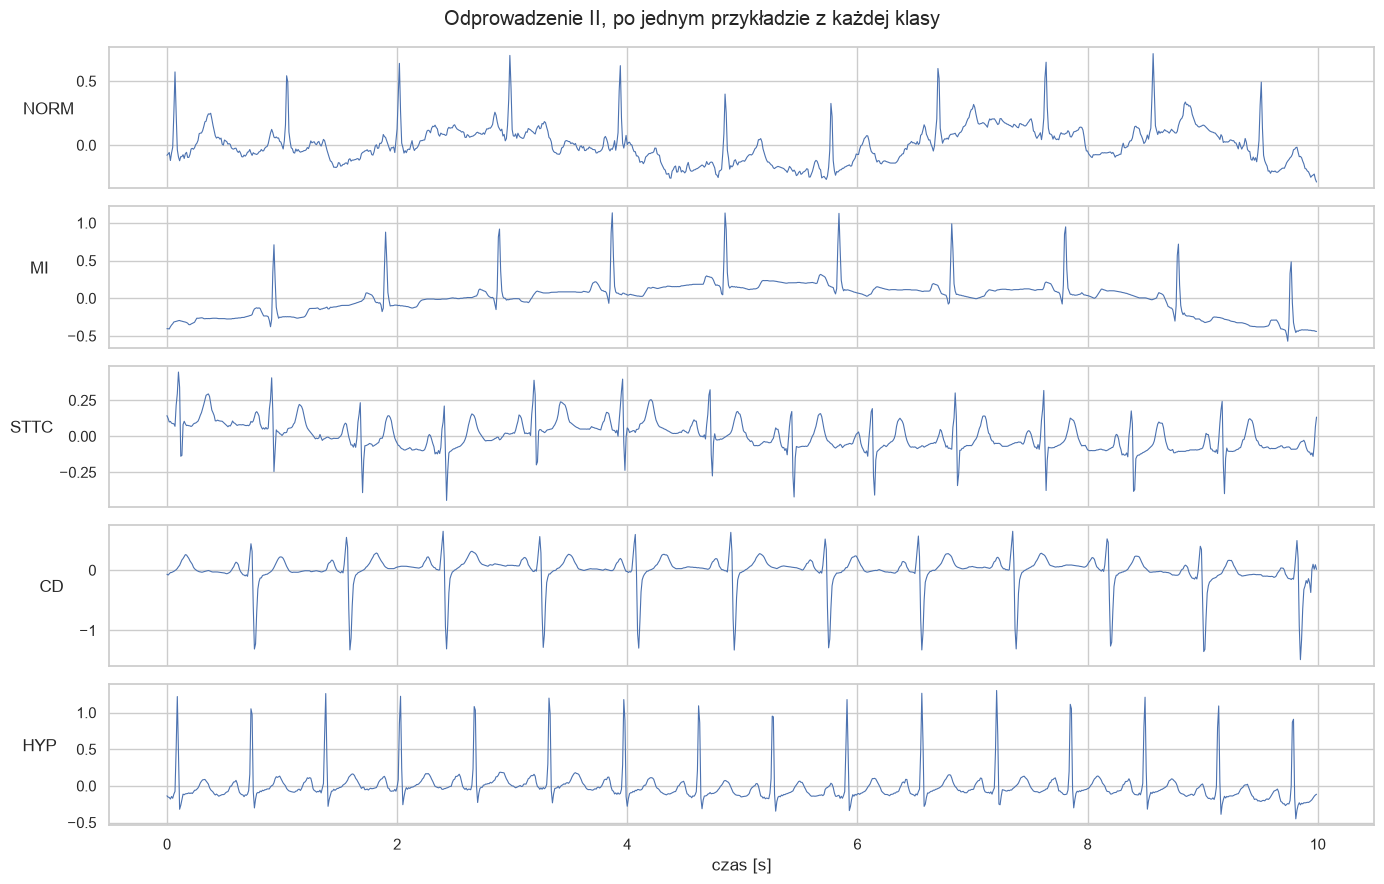

In [19]:
# Po jednym czystym, pewnym przykładzie z każdej klasy (odprowadzenie II)
fig, axes = plt.subplots(len(CLASSES), 1, figsize=(14, 9), sharex=True)
t = np.arange(X.shape[1]) / 100
for ax, cls in zip(axes, CLASSES):
    ecg_id = single[(single.label == cls) & ~single.noisy & (single.likelihood == 100)].index[0]
    ax.plot(t, X[df.index.get_loc(ecg_id), :, 1], lw=0.8)
    ax.set_ylabel(cls, rotation=0, labelpad=20)
axes[-1].set_xlabel("czas [s]")
fig.suptitle("Odprowadzenie II, po jednym przykładzie z każdej klasy")
plt.tight_layout()

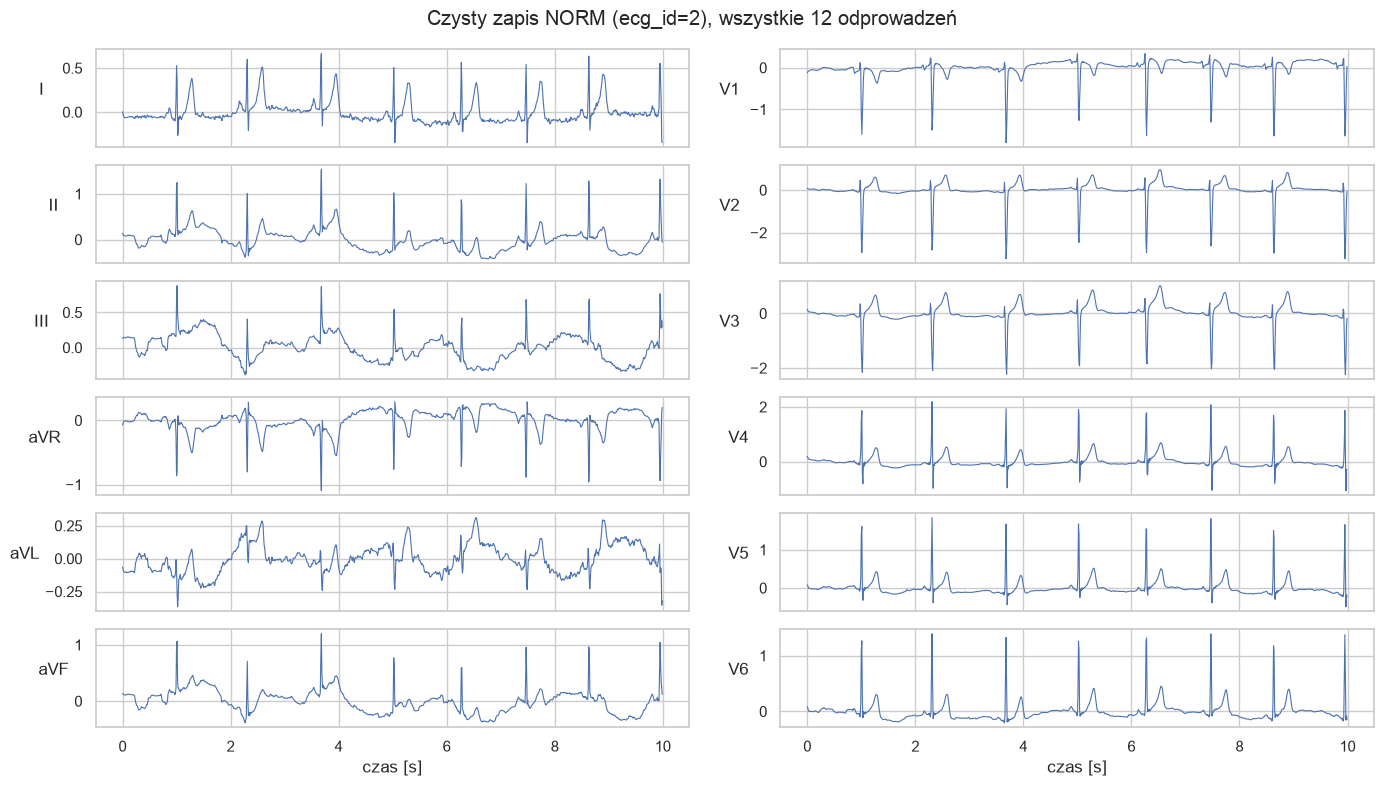

In [20]:
clean_id = single[(single.label == "NORM") & ~single.noisy].index[0]
plot_ecg(clean_id, f"Czysty zapis NORM (ecg_id={clean_id}), wszystkie 12 odprowadzeń")

static_noise            , alles,  
burst_noise                     V5
baseline_drift                 NaN
electrodes_problems            NaN
Name: 38, dtype: str


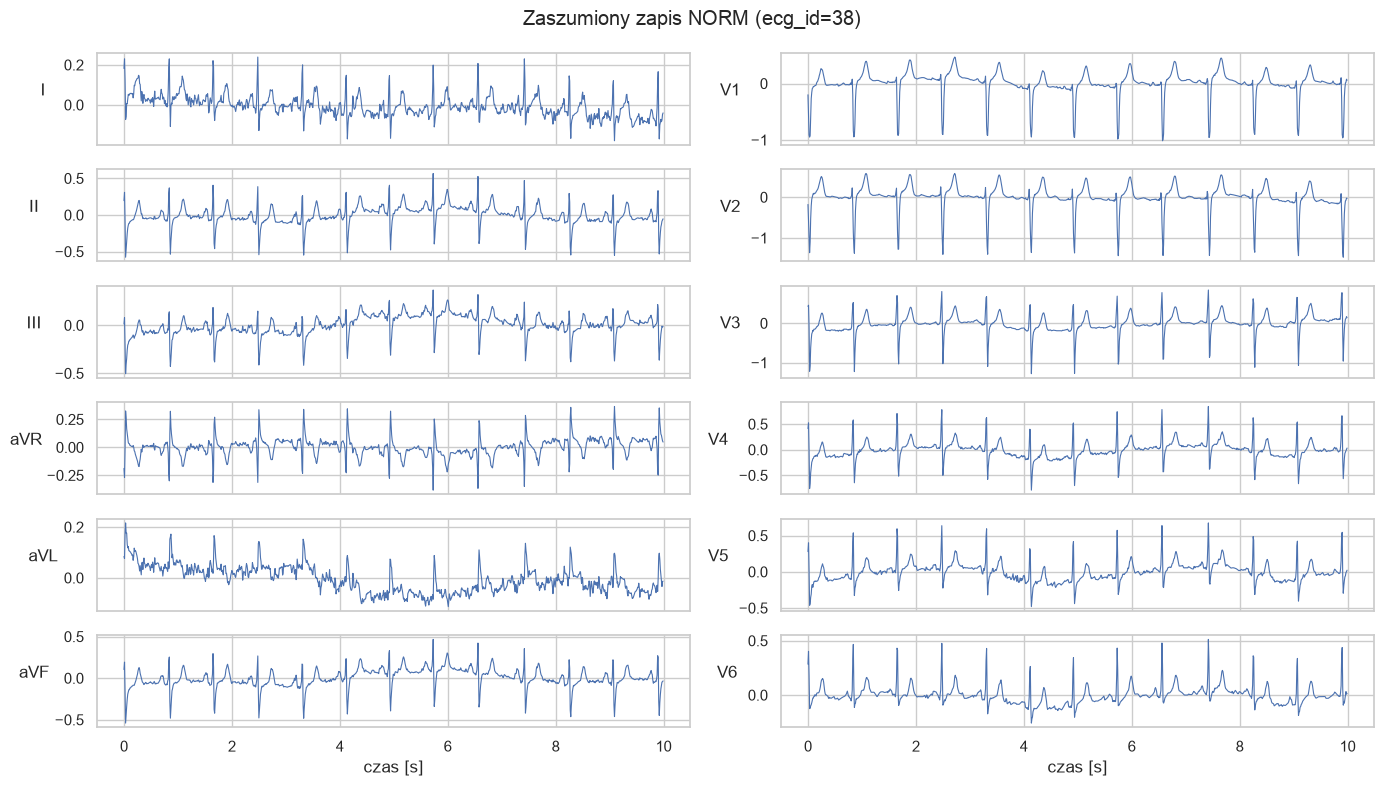

In [21]:
noisy_id = single[(single.label == "NORM") & single.static_noise.notna() & single.burst_noise.notna()].index[0]
print(df.loc[noisy_id, NOISE_COLUMNS])
plot_ecg(noisy_id, f"Zaszumiony zapis NORM (ecg_id={noisy_id})")

### Amplitudy

Sygnał jest w miliwoltach. Sprawdzamy rozkład wartości i wartości skrajne, żeby dobrać normalizację.

In [22]:
lead_stats = pd.DataFrame({
    "średnia": X.mean(axis=(0, 1)),
    "odch. std": X.std(axis=(0, 1)),
    "p0.1%": np.percentile(X[::10], 0.1, axis=(0, 1)),
    "p99.9%": np.percentile(X[::10], 99.9, axis=(0, 1)),
    "min": X.min(axis=(0, 1)),
    "max": X.max(axis=(0, 1)),
}, index=LEADS)
lead_stats.round(3)

,średnia,odch. std,p0.1%,p99.9%,min,max
I,-0.002,0.159,-0.623,1.241,-7.455000,4.398
II,-0.001,0.160,-0.817,1.251,-5.856000,5.576
III,0.001,0.167,-1.326,1.091,-4.656000,7.491
aVR,0.002,0.136,-1.043,0.489,-3.679000,5.920
aVL,-0.001,0.142,-0.688,1.116,-7.473000,4.425
aVF,-0.000,0.143,-1.012,1.047,-5.300000,5.553
V1,0.000,0.229,-2.102,1.223,-17.825001,10.547
V2,-0.001,0.331,-2.973,1.610,-11.102000,12.157
V3,-0.001,0.326,-2.653,1.911,-16.320000,8.505
V4,-0.002,0.298,-1.734,2.285,-11.198000,8.696


Zapisy z |amplitudą| > 5 mV: 307
Zapisy z |amplitudą| > 10 mV: 25


<Axes: title={'center': 'Maksymalna |amplituda| zapisu [mV]'}, ylabel='Frequency'>

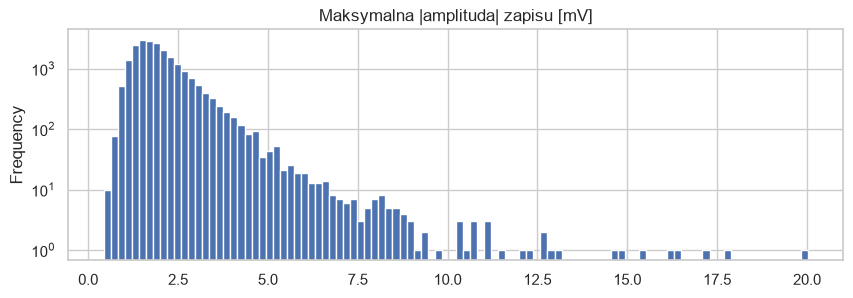

In [23]:
peak = np.abs(X).max(axis=(1, 2))
print("Zapisy z |amplitudą| > 5 mV:", (peak > 5).sum())
print("Zapisy z |amplitudą| > 10 mV:", (peak > 10).sum())
pd.Series(peak).plot.hist(bins=100, logy=True, figsize=(10, 3), title="Maksymalna |amplituda| zapisu [mV]")

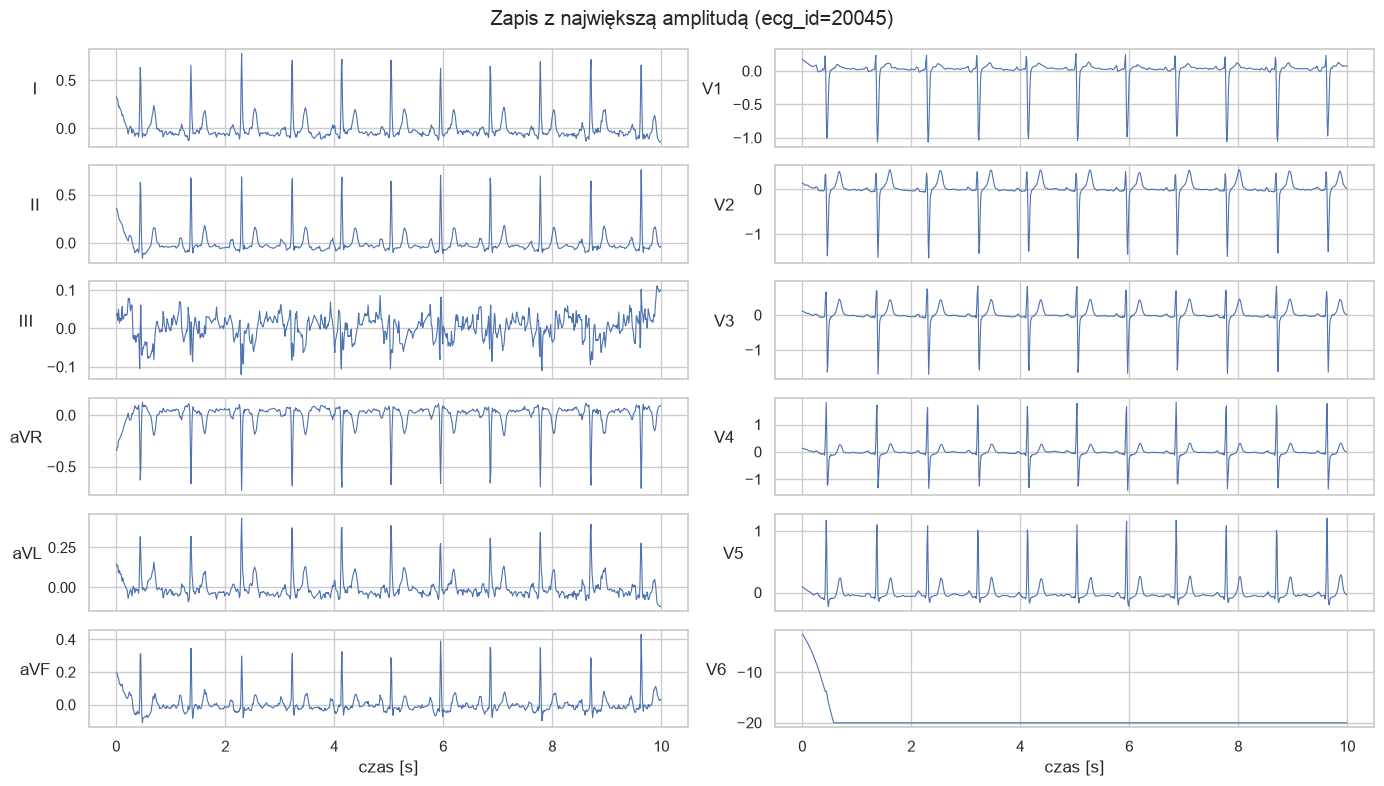

In [24]:
plot_ecg(df.index[peak.argmax()], f"Zapis z największą amplitudą (ecg_id={df.index[peak.argmax()]})")

Zapis z największą amplitudą to artefakt: odpięta elektroda w V6 (sygnał nasycony na -20 mV).
W bazie oznaczono go jako `electrodes_problems = V5`, czyli adnotacja jest, ale wskazuje inne odprowadzenie.

In [25]:
big = df[peak > 5]
print(f"Zapisy z |amplitudą| > 5 mV: {len(big)}, z adnotacją szumu: {big.noisy.mean():.0%} "
      f"(w całej bazie: {df.noisy.mean():.0%})")

Zapisy z |amplitudą| > 5 mV: 307, z adnotacją szumu: 50% (w całej bazie: 23%)


## 6. Wnioski

**Kompletność.** 21 837 zapisów, brak brakujących wartości w sygnałach, podział `strat_fold` nie miesza pacjentów między zbiorami.

**Niezbalansowane klasy.** NORM to 56% zapisów z jedną nadklasą, HYP tylko 3% (56 zapisów w teście).
Potrzebne będą wagi klas i metryki macro-F1 / balanced accuracy, a wyniki dla HYP będą mało stabilne.

**Zapisy z jedną nadklasą.** Zostaje 16 272 z 21 837 (75%). Odpadają głównie kombinacje typu CD+MI i HYP+STTC.
HYP prawie zawsze występuje razem z inną klasą, dlatego w wersji jednoetykietowej jest go tak mało.

**Pewność diagnozy zależy od klasy.**
- HYP: 75% etykiet ma pewność < 100, MI: 47% (aż 24% ma pewność 15, czyli „podejrzenie”).
- CD i STTC: prawie zawsze 100.
- To prawdziwy szum etykiet, ale też pułapka: porównując niepewność modelu z pewnością diagnozy,
  trzeba to robić **w obrębie jednej klasy**, inaczej zmierzymy po prostu różnicę między klasami.

**Jakość sygnału.** 23% zapisów ma adnotację problemu, głównie `static_noise` (15%).
Adnotacje są przybliżone: zapis 38 oznaczony jako zaszumiony na wszystkich odprowadzeniach wygląda dość czysto,
a odpięta elektroda w zapisie 20045 jest przypisana do złego odprowadzenia. Traktujemy je jako wskazówkę, nie pewnik.

**Weryfikacja opisu.** 24% zapisów z jedną nadklasą nie ma potwierdzonego opisu. Najgorzej MI: tylko 56% potwierdzonych.

**Amplitudy.** Odchylenie standardowe 0,14–0,33 mV zależnie od odprowadzenia, ale skrajne wartości sięgają ±20 mV
(307 zapisów powyżej 5 mV, połowa z adnotacją szumu). Propozycja: przyciąć wartości (np. do ±5 mV)
i standaryzować każde odprowadzenie statystykami ze zbioru treningowego. Zapisów nie usuwamy, bo to część naturalnego szumu.

**Następny krok:** przygotowanie danych do treningu (normalizacja, podział, wagi klas) i model bazowy A.